# Project 4 starter: noise, characterisation and error mitigation

Setup and building blocks for [Project 4](../../content/outline/projects.md). The notebook is organised around the four core elements, in the same order as the main tasks. Code you need but that isn't the point of the project (device properties, placing circuits on chosen qubits, running and logging jobs, an optimiser) is provided. The parts marked `TODO` are for you to write, and each has a check so you know when it works. How far you take the investigation from here is up to you.

In [1]:
# ---- Settings: change these to suit your investigation ----
SETTINGS = dict(
    DEVICE="FakeFez",                  # fake backend modelling a real device
    QUBITS=[0, 1, 2, 3, 4, 5],         # chain of connected physical qubits to use
    SHOTS=4000,
    SEED=1234,
)
DEVICE, QUBITS, SHOTS, SEED = (SETTINGS[k] for k in ["DEVICE", "QUBITS", "SHOTS", "SEED"])

In [2]:
import json, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, Operator
from qiskit.primitives import StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit_ibm_runtime import fake_provider

rng = np.random.default_rng(SEED)
backend = getattr(fake_provider, DEVICE)()
print(f"{backend.name}: {backend.num_qubits} qubits, native gates {sorted(backend.target.operation_names)}")

fake_fez: 156 qubits, native gates ['cz', 'delay', 'for_loop', 'id', 'if_else', 'measure', 'reset', 'rz', 'switch_case', 'sx', 'x']


## Your qubits' reported properties

Fake backends contain a snapshot of a real device's calibration data, and their noise model is built from it. Real backends (bonus, see [Running on real quantum computers](../../content/outline/hardwareAccess.md)) have the same `backend.target` interface, with up-to-date values.

In [3]:
target = backend.target
two_qubit_gate = "cz" if "cz" in target.operation_names else "ecr"

print(f"{'qubit':>5} {'T1 (us)':>8} {'T2 (us)':>8} {'readout err':>12} {'sx err':>8}")
for q in QUBITS:
    p = target.qubit_properties[q]
    print(f"{q:>5} {p.t1 * 1e6:8.1f} {p.t2 * 1e6:8.1f} {target['measure'][(q,)].error:12.4f} {target['sx'][(q,)].error:8.5f}")

print(f"\n{two_qubit_gate} errors along the chain:")
for a, b in zip(QUBITS[:-1], QUBITS[1:]):
    props = target[two_qubit_gate].get((a, b)) or target[two_qubit_gate].get((b, a))
    if props is None:
        raise ValueError(f"Qubits {a} and {b} are not connected on {backend.name}: choose a connected chain")
    print(f"  {a}-{b}: {props.error:.4f}")

qubit  T1 (us)  T2 (us)  readout err   sx err
    0     48.8     42.4       0.0115  0.00076
    1    255.7    302.8       0.0117  0.00018
    2    274.4    100.0       0.0049  0.00020
    3    219.7    215.5       0.0159  0.00024
    4    190.9    161.9       0.0015  0.00021
    5    190.0    208.7       0.0076  0.00028

cz errors along the chain:
  0-1: 0.0102
  1-2: 0.0038
  2-3: 0.0030
  3-4: 0.0043
  4-5: 0.0028


## 1. Circuit design

`ghz_circuit(n)` prepares $\frac{1}{\sqrt2}(|0\cdots0\rangle + |1\cdots1\rangle)$ with a chain of CNOTs. `to_device` transpiles circuits for the backend, with `initial_layout` forcing them onto **your** qubits. Otherwise the transpiler would be free to choose, which makes results hard to interpret.

gate counts: {'rz': 14, 'sx': 7, 'measure': 4, 'cz': 3, 'barrier': 1}  depth: 16


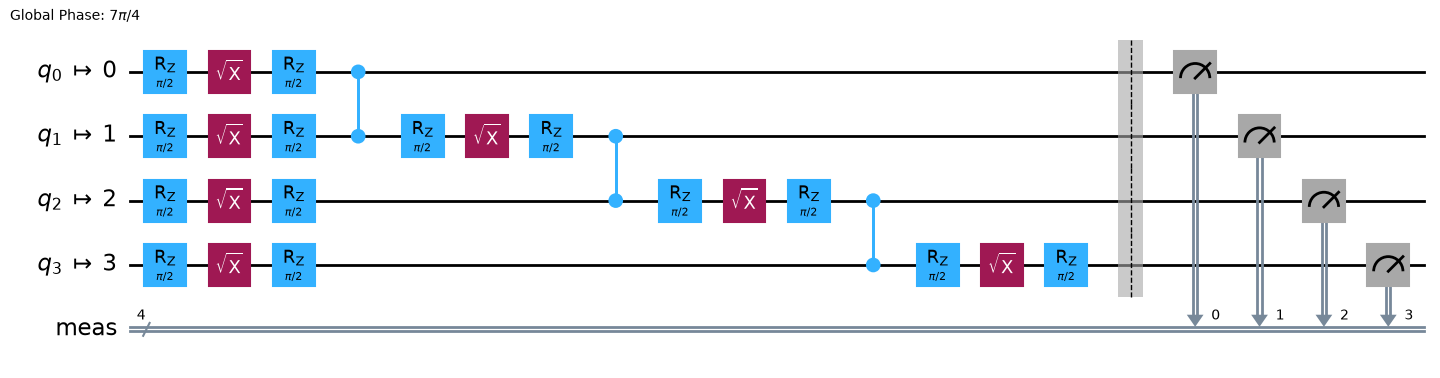

In [4]:
def ghz_circuit(n, measure=True):
    qc = QuantumCircuit(n, name=f"ghz{n}")
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    if measure:
        qc.measure_all()
    return qc

def to_device(circuits, qubits=QUBITS, optimization_level=1):
    circuits = circuits if isinstance(circuits, list) else [circuits]
    pm = generate_preset_pass_manager(backend=backend, optimization_level=optimization_level,
                                      initial_layout=qubits[:circuits[0].num_qubits], seed_transpiler=SEED)
    return pm.run(circuits)

qc4 = to_device(ghz_circuit(4))[0]
print("gate counts:", dict(qc4.count_ops()), " depth:", qc4.depth())
qc4.draw("mpl", idle_wires=False, fold=-1)

## 2. Measurement and uncertainty

A **run function** takes a list of circuits (with measurements) and returns their counts. `ideal_run` simulates them without noise. `device_run(label)` transpiles them onto your qubits, runs them on the backend, and appends every result (backend, job ID, qubits, shots, time, counts) to `results/runs.jsonl`. Keep this log: it is your lab notebook. Writing your estimators in terms of a run function means the same code works on the ideal simulator, the fake backend and real hardware.

In [5]:
LOG = Path("results/runs.jsonl")

def ideal_run(circuits, shots=SHOTS):
    res = StatevectorSampler(seed=SEED).run(circuits, shots=shots).result()
    return [r.data.meas.get_counts() for r in res]

def device_run(label="", shots=SHOTS, optimization_level=1):
    def run(circuits):
        sampler = Sampler(mode=backend)
        if backend.name.startswith("fake"):
            sampler.options.simulator.seed_simulator = int(rng.integers(1e9))
        job = sampler.run(to_device(circuits, optimization_level=optimization_level), shots=shots)
        all_counts = [r.data.meas.get_counts() for r in job.result()]
        LOG.parent.mkdir(exist_ok=True)
        with LOG.open("a") as f:
            for qc, counts in zip(circuits, all_counts):
                f.write(json.dumps({"label": label, "circuit": qc.name, "backend": backend.name, "job_id": job.job_id(),
                                    "qubits": QUBITS[:qc.num_qubits], "shots": shots, "time": time.ctime(),
                                    "counts": counts}) + "\n")
        return all_counts
    return run

def load_log(label=None):
    records = [json.loads(line) for line in LOG.read_text().splitlines()]
    return [r for r in records if label is None or r["label"] == label]

def expectation_from_counts(counts, qubits):
    # <Z...Z> on the given (circuit) qubits from counts. Bit strings are read right to left.
    shots = sum(counts.values())
    return sum((-1) ** sum(int(b[-1 - q]) for q in qubits) * n for b, n in counts.items()) / shots

counts = device_run("example")([ghz_circuit(3)])[0]
print("GHZ-3 on the noisy device:", dict(sorted(counts.items(), key=lambda kv: -kv[1])[:4]), "...")
print("<Z0 Z1> =", round(expectation_from_counts(counts, [0, 1]), 3))

GHZ-3 on the noisy device: {'111': 1936, '000': 1905, '110': 47, '001': 37} ...
<Z0 Z1> = 0.937


### GHZ fidelity and readout errors (to implement)

`estimate_ghz_fidelity(prep, run)` should return the fidelity of the state prepared by the circuit `prep` (no measurements) with the ideal GHZ state, together with its standard error, using only circuits executed by `run`. Note that $P(0\cdots0)+P(1\cdots1)$ is **not** the fidelity: a classical mixture of $|0\cdots0\rangle$ and $|1\cdots1\rangle$ would also give 1.

`readout_calibration(n, run)` should measure the readout (assignment) errors of your qubits, and `mitigate_counts` should use the result to correct measured counts or probabilities. Choose the form of the calibration data yourself.

In [6]:
def estimate_ghz_fidelity(prep, run):
    """Fidelity of the state prepared by `prep` with the n-qubit GHZ state, and its standard error."""
    raise NotImplementedError("TODO")

def readout_calibration(n, run):
    """Measure the readout errors of the first n qubits of your chain. Returns calibration data of your choice."""
    raise NotImplementedError("TODO")

def mitigate_counts(counts, calibration):
    """Correct measured counts for readout errors using `calibration`."""
    raise NotImplementedError("TODO")

In [7]:
try:
    for n in [2, 3, 4]:
        F, dF = estimate_ghz_fidelity(ghz_circuit(n, measure=False), ideal_run)
        print(f"ideal GHZ-{n}: F = {F:.3f} ± {dF:.3f}  (should be 1 within errors)")
    F, dF = estimate_ghz_fidelity(QuantumCircuit(3), ideal_run)
    print(f"|000>:       F = {F:.3f} ± {dF:.3f}  (should be 0.5)")
except NotImplementedError:
    print("estimate_ghz_fidelity: not implemented yet")

try:
    cal = readout_calibration(len(QUBITS), device_run("readout-calibration"))
    print("calibration:", cal)
    print("compare with the reported readout errors:", [round(target['measure'][(q,)].error, 4) for q in QUBITS])
except NotImplementedError:
    print("readout_calibration: not implemented yet")

estimate_ghz_fidelity: not implemented yet
readout_calibration: not implemented yet


## 3. Optimisation and gradients

### Gradient methods (to implement)

Implement the three gradient methods from [Lecture 5](../../content/lectures/lecture5.md). Each takes a function `f` and parameters `theta` (shape `(P,)`), and returns an estimate of $\nabla f$. `f` accepts a whole **batch** of parameter sets, with shape `(N, P)`, and returns `N` values. Evaluate everything you need in a single call to `f`, which is much faster.

`check_gradient` compares your implementation with a high-accuracy reference using exact (noiseless) values, and prints the relative error. Finite difference (with a small step) and parameter shift should agree to many digits. SPSA is random, so its check averages many estimates. The error of the average only falls as $1/\sqrt{n}$, so a relative error of order $10^{-1}$ to $10^{-2}$ is expected.

For the check, `f_exact` is the exact fidelity of the parametrised state `ghz_ansatz(n)` with the GHZ state. This is the expectation value of the projector $|\mathrm{GHZ}\rangle\langle\mathrm{GHZ}|$, so the parameter-shift rule applies. At $\theta = (\pi/2, 0, \dots, 0)$ the ansatz prepares the GHZ state exactly.

In [8]:
def finite_difference_gradient(f, theta, c=0.1):
    """Central finite-difference estimate of the gradient of f at theta."""
    raise NotImplementedError("TODO")

def spsa_gradient(f, theta, c=0.1, rng=rng):
    """SPSA estimate of the gradient of f at theta, using only two evaluations of f."""
    raise NotImplementedError("TODO")

def parameter_shift_gradient(f, theta):
    """Parameter-shift gradient of f at theta. Exact when f is an expectation value of a circuit
    whose parameters each appear once, in a Pauli rotation gate."""
    raise NotImplementedError("TODO")


def check_gradient(gradient_fn, f_exact, theta, n_average=1, **kwargs):
    """Compare gradient_fn(f_exact, theta) (averaged over n_average estimates) with a reference."""
    try:
        g = np.mean([gradient_fn(f_exact, theta, **kwargs) for _ in range(n_average)], axis=0)
    except NotImplementedError:
        print(f"{gradient_fn.__name__}: not implemented yet")
        return
    eps, P = 1e-5, len(theta)
    vals = f_exact(theta + np.vstack([eps * np.eye(P), -eps * np.eye(P)]))
    reference = (vals[:P] - vals[P:]) / (2 * eps)
    rel = np.max(np.abs(g - reference)) / np.max(np.abs(reference))
    print(f"{gradient_fn.__name__}: relative error = {rel:.1e}" + (f" (average of {n_average})" if n_average > 1 else ""))


def ghz_ansatz(n):
    theta = ParameterVector("θ", n)
    qc = QuantumCircuit(n)
    qc.ry(theta[0], 0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
        qc.ry(theta[i + 1], i + 1)
    return qc

def exact_fidelity_function(n):
    ansatz, ghz = ghz_ansatz(n), Statevector(ghz_circuit(n, measure=False))
    return lambda thetas: np.array([abs(ghz.inner(Statevector(ansatz.assign_parameters(t)))) ** 2
                                    for t in np.atleast_2d(thetas)])

In [9]:
f_exact = exact_fidelity_function(3)
theta_test = rng.uniform(0, 2 * np.pi, 3)

check_gradient(finite_difference_gradient, f_exact, theta_test, c=1e-4)
check_gradient(spsa_gradient, f_exact, theta_test, n_average=2000, c=1e-4)
check_gradient(parameter_shift_gradient, f_exact, theta_test)

finite_difference_gradient: not implemented yet
spsa_gradient: not implemented yet
parameter_shift_gradient: not implemented yet


### Optimising on the noisy device

`gradient_descent` minimises a function, so to maximise the fidelity we minimise $1-F$. Once your fidelity estimator and gradients work, you can optimise the ansatz on the noisy device, measuring the fidelity with your own estimator. For example:

```python
run = device_run("optimisation")
n_runs = 0
def infidelity(thetas):
    global n_runs
    n_runs += len(thetas)
    return np.array([1 - estimate_ghz_fidelity(ghz_ansatz(3).assign_parameters(t), run)[0] for t in thetas])

theta, history = gradient_descent(infidelity, theta_test, spsa_gradient, eta=0.2, iterations=30,
                                  cost=lambda: n_runs)
```

Simulating a noisy device is slow. Each fidelity estimate runs $n+1$ circuits on the fake backend, so a parameter-shift step for 3 qubits takes about half a minute on a laptop. Start small, think about which gradient method makes sense, and use the HPC for longer runs.

In [10]:
def gradient_descent(f, theta0, gradient_fn, eta=0.1, iterations=50, cost=None, **grad_kwargs):
    """Plain gradient descent on f. Records f (one extra evaluation per step), the parameters,
    and the cost so far, if `cost` is a function returning it."""
    theta = np.array(theta0, dtype=float)
    history = {"f": [], "theta": [], "cost": []}
    for _ in range(iterations):
        history["f"].append(f(theta[None])[0])
        history["theta"].append(theta.copy())
        history["cost"].append(cost() if cost else np.nan)
        theta = theta - eta * gradient_fn(f, theta, **grad_kwargs)
    return theta, {k: np.array(v) for k, v in history.items()}

## 4. Noise

For zero-noise extrapolation you need circuits that do the same thing as the original but with amplified noise. `fold_two_qubit_gates(circuit, scale)` should replace each two-qubit gate $G$ by $G\,(G^\dagger G)^k$ with `scale` $=2k+1$. Apply it to the circuit **after** transpiling to the device (and make sure later transpilation doesn't simplify it away). The check confirms that a folded circuit is still the same unitary, with `scale` times as many two-qubit gates.

In [11]:
def fold_two_qubit_gates(circuit, scale):
    """Copy of `circuit` with every two-qubit gate G replaced by G (G^dagger G)^k, where scale = 2k + 1."""
    raise NotImplementedError("TODO")

In [12]:
try:
    qc = ghz_circuit(4, measure=False)
    for scale in [1, 3, 5]:
        folded = fold_two_qubit_gates(qc, scale)
        same = Operator(folded).equiv(Operator(qc))
        n2 = sum(1 for inst in folded.data if inst.operation.num_qubits == 2)
        print(f"scale {scale}: same unitary: {same}, two-qubit gates: {n2} (expected {scale * 3})")
except NotImplementedError:
    print("fold_two_qubit_gates: not implemented yet")

fold_two_qubit_gates: not implemented yet


## Saving results

Your runs are logged automatically in `results/runs.jsonl`. Save other results (e.g. analysis) as you go.

In [13]:
def save_results(name, **arrays):
    """Save numpy arrays to results/<name>.npz, with the group settings in results/<name>.json."""
    out = Path("results"); out.mkdir(exist_ok=True)
    np.savez(out / f"{name}.npz", **arrays)
    (out / f"{name}.json").write_text(json.dumps({**SETTINGS, "time": time.ctime()}, indent=2, default=str))